# Inverse Problems 2026 - Exercise 2 (home exercises)

Return by **Fri 13.11.2026 at 23:59** in Moodle! You can ask for help with these exercises in the exercise session the same day (10:00, room 7334).

The returned exercises should be renamed `Exercise02_lastname_firstname.ipynb` and contain your solutions in clear and readable manner and format. The programming exercises need to be runnable with minimal effort. If you find markdown too cumbersome for writing the necessary math, you can attach **a single extra pdf-file** for the theoretical exercises and denote it `Exercise02_lastname_firstname.pdf`.

___
In the following exercises you should use the given data `y`, forward operator `A` and ground truth `gt`.
___

In [17]:
import numpy as np
import scipy.linalg as la

n = 100
x = np.linspace(0, 1, n)

psf = np.array([0.02, 0.08, 0.13, 0.17, 0.19, 0.17, 0.13, 0.08, 0.02])
A = la.convolution_matrix(psf, n, mode="same")
gt = np.array([0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
        0.  , 1.5 , 1.5 , 1.5 , 0.  , 0.  , 0.  , 0.  , 0.  , 1.3 , 1.3 ,
        1.3 , 1.3 , 1.3 , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
        0.  , 0.  , 0.02, 0.07, 0.12, 0.17, 0.22, 0.27, 0.32, 0.37, 0.42,
        0.47, 0.52, 0.57, 0.62, 0.67, 0.72, 0.78, 0.83, 0.88, 0.93, 0.98,
        0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
        0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 1.  , 1.  ,
        1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 1.  , 0.  , 0.  , 0.  ,
        0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
        0.  ])
y = np.array([ 1.98e-02, -6.76e-02,  4.88e-02,  6.11e-02, -1.27e-01, -8.46e-02,
        8.31e-03, -2.06e-02, -1.09e-03, -5.54e-02,  9.36e-02,  4.01e-01,
        8.95e-01,  1.39e+00,  1.18e+00,  5.54e-01,  1.76e-01, -6.23e-02,
        8.87e-02,  3.00e-01,  7.60e-01,  1.12e+00,  1.38e+00,  1.26e+00,
        9.69e-01,  5.05e-01,  1.66e-01,  2.38e-02,  2.68e-02,  2.80e-02,
        1.39e-01, -2.64e-02, -3.33e-02, -5.27e-02,  4.52e-02,  9.78e-02,
        5.39e-02,  5.47e-02,  1.06e-01,  2.52e-01,  3.08e-01,  3.46e-01,
        3.17e-01,  4.26e-01,  4.69e-01,  5.26e-01,  6.18e-01,  6.26e-01,
        7.06e-01,  7.17e-01,  7.81e-01,  8.54e-01,  7.68e-01,  8.68e-01,
        6.93e-01,  3.51e-01,  8.15e-02,  9.72e-02, -5.63e-02,  6.29e-02,
        -1.09e-01, -2.18e-02,  1.06e-02,  3.81e-02,  4.62e-02,  5.16e-02,
        -2.27e-02, -3.01e-02,  5.58e-02, -1.24e-02, -8.29e-02, -7.37e-02,
        -5.98e-02,  5.66e-02,  2.43e-01,  6.39e-01,  8.71e-01,  1.01e+00,
        1.04e+00,  9.80e-01,  1.03e+00,  9.57e-01,  9.76e-01,  9.51e-01,
        6.89e-01,  4.38e-01,  7.06e-02,  8.12e-04,  3.12e-02,  2.90e-02,
        4.33e-02, -6.40e-03, -2.75e-02, -5.18e-03, -1.10e-01, -9.41e-02,
        -8.60e-02, -6.48e-02,  2.60e-02, -5.89e-02])

## Task 1 (Tikhonov regularization)
Using the given forward matrix `A` and vector `y`, solve the Tikhonov regularized solution for regularization parameters $\alpha = 0.01, 0.1$ and $1$ and plot the result.

The lecture notes (Section 2.3) define the zero-order Tikhonov solution as
$$
x_\alpha=\underset{z\in\mathbb{R}^{100}}{\operatorname{argmin}}
\left(\|Az-y\|_2^2+\alpha\|z\|_2^2\right),
\qquad
(A^\top A+\alpha I)x_\alpha=A^\top y.
$$
For each requested $\alpha>0$, the coefficient matrix is positive definite. I solve this linear system directly, rather than explicitly forming its inverse. The supplied `gt` is used to assess the reconstructions and to estimate the measurement-noise vector $y-A\,gt$; it is never used to calculate $x_\alpha$. For a discrepancy comparison, the relevant noise quantity is the norm $\delta=\|y-A\,gt\|_2$, not the standard deviation of individual noise entries.


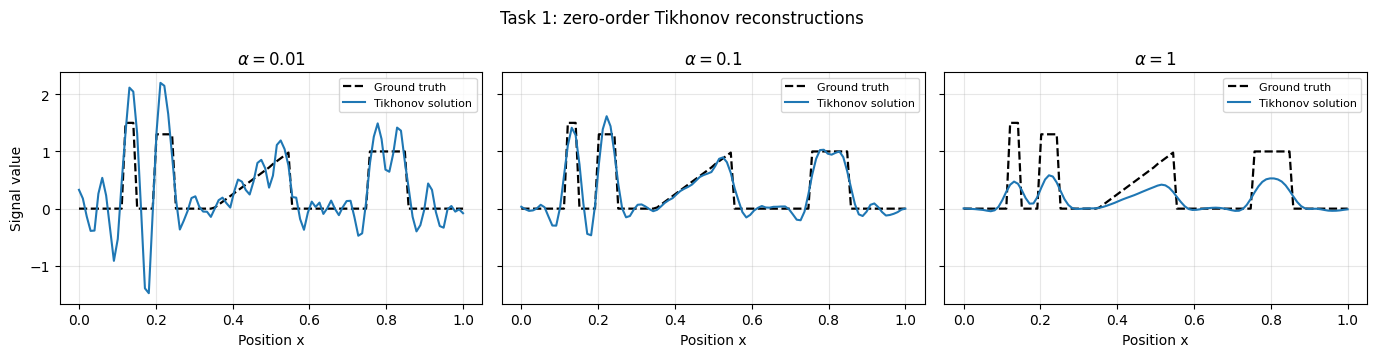

Estimated noise norm ||y - A gt||_2 = 1.3208
Sample noise standard deviation per entry = 0.1327
alpha    ||A x_alpha - y||_2    ||x_alpha||_2    relative error to gt
 0.01                0.6317           7.4432                67.09%
 0.10                1.1966           5.3994                33.38%
 1.00                3.1102           2.4313                62.39%


In [18]:
import matplotlib.pyplot as plt

# Evaluate exactly the three regularization strengths specified in Task 1
alphas = (0.01, 0.1, 1.0)

# Step 1: Precompute the terms shared by the Tikhonov normal equations
normal_matrix = A.T @ A
right_hand_side = A.T @ y
identity = np.eye(A.shape[1])

# Step 2: Solve (A.T @ A + alpha I) x_alpha = A.T @ y for each alpha
# A positive-definite solve avoids explicitly forming a matrix inverse
solutions = {
    alpha: la.solve(normal_matrix + alpha * identity,
                    right_hand_side, assume_a="pos")
    for alpha in alphas
}

# Step 3: Compare each reconstruction with the supplied ground truth on common axes
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True, sharey=True)
for ax, alpha in zip(axes, alphas):
    reconstruction = solutions[alpha]
    ax.plot(x, gt, "k--", linewidth=1.6, label="Ground truth")
    ax.plot(x, reconstruction, linewidth=1.5, label="Tikhonov solution")
    ax.set(title=fr"$\alpha={alpha:g}$", xlabel="Position x")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)
axes[0].set_ylabel("Signal value")
fig.suptitle("Task 1: zero-order Tikhonov reconstructions")
fig.tight_layout()
plt.show()

# Step 4: Estimate the noise from the supplied ground truth for diagnostic purposes
# Its vector norm is the discrepancy target, and standard deviation is per entry
noise = y - A @ gt
noise_norm = la.norm(noise)
noise_std = np.std(noise, ddof=1)
print(f"Estimated noise norm ||y - A gt||_2 = {noise_norm:.4f}")
print(f"Sample noise standard deviation per entry = {noise_std:.4f}")

# Report data fit, solution size, and accuracy for interpreting the trade-off
print("alpha    ||A x_alpha - y||_2    ||x_alpha||_2    relative error to gt")
for alpha, reconstruction in solutions.items():
    residual = la.norm(A @ reconstruction - y)
    solution_norm = la.norm(reconstruction)
    relative_error = la.norm(reconstruction - gt) / la.norm(gt)
    print(f"{alpha:5.2f}    {residual:18.4f}    {solution_norm:13.4f}    {relative_error:18.2%}")


**Result.** The supplied `gt` gives an estimated noise norm $\delta=\|y-A\,gt\|_2\approx1.321$. 

The sample standard deviation of its 100 entries is about $0.133$. These are different quantities. The data residuals $\|Ax_\alpha-y\|_2$ are about $0.632$, $1.197$, and $3.110$ for $\alpha=0.01$, $0.1$, and $1$, respectively. Among the three assigned values, $\alpha=0.1$ has the residual nearest the estimated noise norm. The smaller value fits below the noise level and shows pronounced oscillations. 

$\alpha=1$ gives a much larger residual and suppresses the peaks and ramp. As a separate check using the known ground truth, $\alpha=0.1$ also has the smallest relative error (33.4%, versus 67.1% and 62.4%). This comparison depends on these data and is not a universal parameter rule.


___
## Task 2 (Iterative regularization)
Write a routine that implements the Landweber iterative method discussed in the lectures for $k = 2,7,25$ and $50$ iterations. Use $\beta = 1 / {\lambda^2_1}$.

For the linear forward map $F(z)=Az$, the Landweber update from the lecture notes (Section 4.3) is
$$
x^{(k+1)}=x^{(k)}+\beta A^\top\bigl(y-Ax^{(k)}\bigr),
\qquad x^{(0)}=0,
\qquad \beta=\frac{1}{\lambda_1^2},
$$
where $\lambda_1=\|A\|_2$ is the largest singular value. This is gradient descent on $\tfrac12\|Az-y\|_2^2$; stopping after a finite number of iterations provides regularization. The supplied `gt` is used only for plotting and diagnostic error measurements, never in the updates.


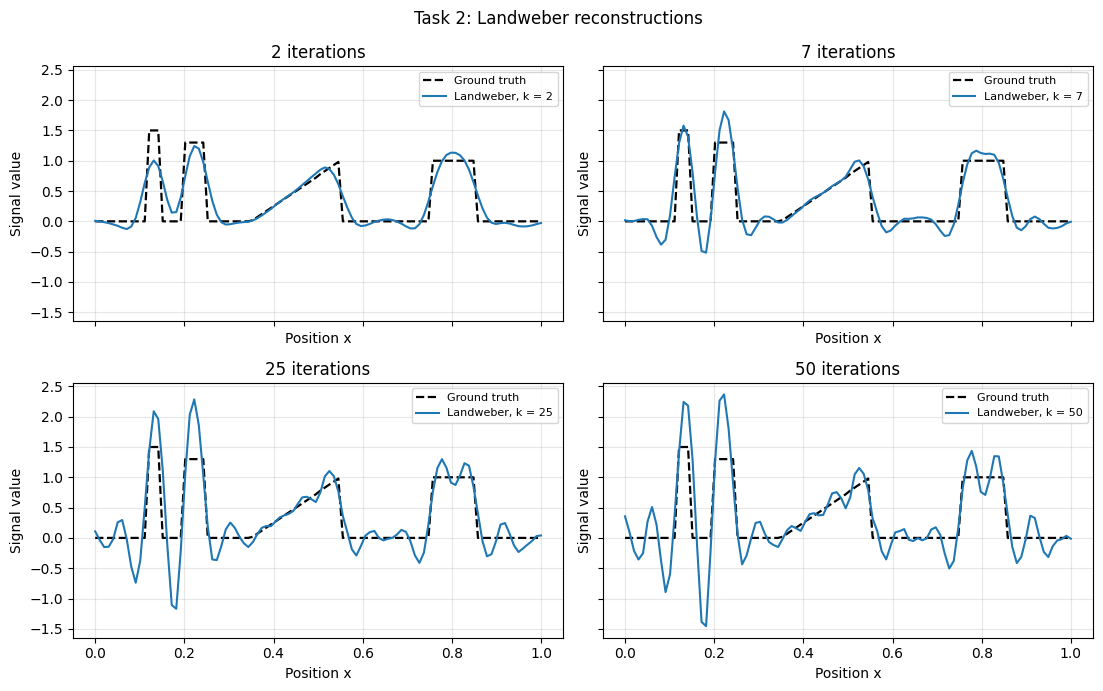

Largest singular value = 0.988364; step size beta = 1.023684
k     ||A x_k - y||_2    relative error to gt
 2                1.5630                37.82%
 7                1.0141                37.08%
25                0.7032                56.10%
50                0.6299                67.98%


In [19]:
# Step 5: Use the assignment's step size based on the largest singular value of A
iteration_counts = (2, 7, 25, 50)
lambda_1 = la.svdvals(A)[0]
beta = 1.0 / lambda_1**2

# Step 6: Start at zero and retain independent copies at the requested iterations
landweber_x = np.zeros(A.shape[1])
landweber_reconstructions = {}
for k in range(1, max(iteration_counts) + 1):
    landweber_x = landweber_x + beta * (A.T @ (y - A @ landweber_x))
    if k in iteration_counts:
        landweber_reconstructions[k] = landweber_x.copy()

# Step 7: Compare the four iterates with the supplied ground truth on common axes
fig2, axes2 = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, k in zip(axes2.flat, iteration_counts):
    ax.plot(x, gt, "k--", linewidth=1.6, label="Ground truth")
    ax.plot(x, landweber_reconstructions[k], linewidth=1.5,
            label=f"Landweber, k = {k}")
    ax.set(title=f"{k} iterations", xlabel="Position x", ylabel="Signal value")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)
fig2.suptitle("Task 2: Landweber reconstructions")
fig2.tight_layout()
plt.show()

# Residuals measure data fit, and errors against gt are available only in this example
print(f"Largest singular value = {lambda_1:.6f}; step size beta = {beta:.6f}")
print("k     ||A x_k - y||_2    relative error to gt")
for k, reconstruction in landweber_reconstructions.items():
    residual = la.norm(A @ reconstruction - y)
    relative_error = la.norm(reconstruction - gt) / la.norm(gt)
    print(f"{k:2d}    {residual:18.4f}    {relative_error:18.2%}")


**Result.** The data residual decreases as the iteration count rises: approximately $1.563$, $1.014$, $0.703$, and $0.630$ at $k=2,7,25,50$. The two early iterates recover the main features, with 25 and especially 50 iterations, finer oscillations become more visible as the method fits the noisy data more closely. 

Among the four requested iterates, $k=7$ has the smallest relative error against the supplied ground truth (about 37.1%). This error is a diagnostic available because `gt` is supplied. It is not part of the Landweber update or a general stopping rule.


___
## Task 3 (Morozov discrepancy)
Try to figure out the size (norm) of the measurement noise in vector `y`. What are the parameters $k$ and $\alpha$ in the previous two exercises that are indicated by the Morozov discrepancy rule? A rough answer is ok.

The lecture notes (Section 2.2) state Morozov's rule as the **first** iteration with $\|Ax^{(k)}-y\|_2\leq\tau\delta$, where $\tau>1$ and $\delta$ bounds the noise **norm**. I use $\tau=1.1$ and estimate $\delta=\|y-A\,gt\|_2$ from the supplied `gt`. The sample standard deviation describes a *single entry* of this noise vector and is not the threshold for a 100-entry residual.

For Tikhonov regularization, $\|Ax_\alpha-y\|_2$ increases with $\alpha$ (Section 2.3). The discrepancy choice is therefore the largest $\alpha$ whose residual is at most $\tau\delta$; with a continuous parameter, it satisfies $\|Ax_\alpha-y\|_2=\tau\delta$. The supplied `gt` enters only the noise estimate and the optional error comparisons below, not either reconstruction or the residual-based parameter search.


Noise norm delta = 1.3208; sample standard deviation = 0.1327
Threshold tau*delta = 1.4529 (tau = 1.1)
Landweber: r(2) = 1.5630, r(3) = 1.3682; first crossing k = 3
Tikhonov: alpha = 0.1589, r(alpha) = 1.4529
Among previously plotted values: k = 7, alpha = 0.1
Relative errors using gt (diagnostic only): k = 3: 35.12%; alpha = 0.1589: 33.53%


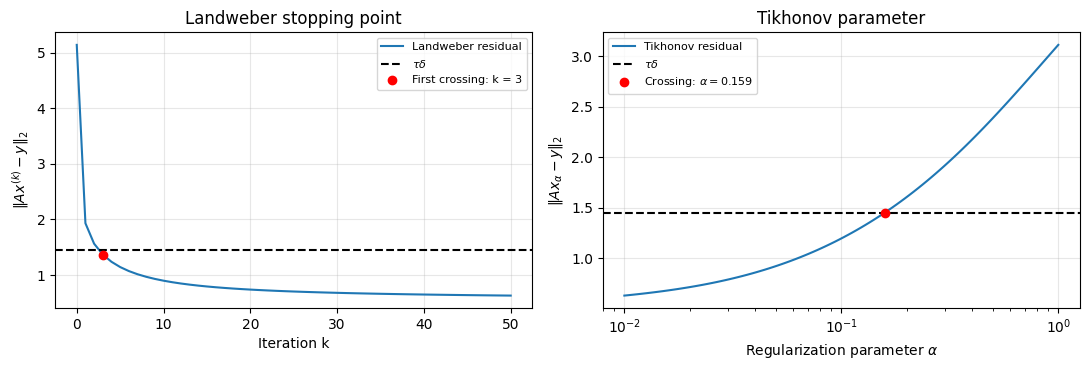

In [20]:
from scipy.optimize import brentq

# Step 8: Estimate the noise norm using the supplied ground truth, then set the
# discrepancy threshold. Standard deviation is reported separately per entry
disc_noise = y - A @ gt
disc_delta = la.norm(disc_noise)
disc_sigma = np.std(disc_noise, ddof=1)
disc_tau = 1.1
disc_threshold = disc_tau * disc_delta

# Step 9: Recompute the Landweber residual at every iteration, including k = 0
# Stop at the first k >= 1 whose residual reaches the threshold.
disc_beta = 1.0 / la.svdvals(A)[0]**2
disc_iterates = [np.zeros(A.shape[1])]
for k in range(1, 51):
    previous = disc_iterates[-1]
    disc_iterates.append(previous + disc_beta * A.T @ (y - A @ previous))
disc_residuals_k = np.array([la.norm(A @ z - y) for z in disc_iterates])
disc_k = next(k for k in range(1, len(disc_iterates))
              if disc_residuals_k[k] <= disc_threshold)

# Step 10: Solve the Tikhonov normal equations and find the residual crossing in alpha
disc_gram = A.T @ A
disc_rhs = A.T @ y
disc_identity = np.eye(A.shape[1])
def disc_tikhonov(alpha):
    return la.solve(disc_gram + alpha * disc_identity,
                    disc_rhs, assume_a="pos")
def disc_residual_alpha(alpha):
    return la.norm(A @ disc_tikhonov(alpha) - y)

disc_alpha = brentq(lambda alpha: disc_residual_alpha(alpha) - disc_threshold,
                    0.01, 1.0)

# Step 11: Compare the continuous discrepancy choices with the parameters plotted above
disc_k_candidates = (2, 7, 25, 50)
disc_alpha_candidates = (0.01, 0.1, 1.0)
disc_k_displayed = next(k for k in disc_k_candidates
                        if disc_residuals_k[k] <= disc_threshold)
disc_alpha_displayed = max(alpha for alpha in disc_alpha_candidates
                           if disc_residual_alpha(alpha) <= disc_threshold)

print(f"Noise norm delta = {disc_delta:.4f}; sample standard deviation = {disc_sigma:.4f}")
print(f"Threshold tau*delta = {disc_threshold:.4f} (tau = {disc_tau:g})")
print(f"Landweber: r(2) = {disc_residuals_k[2]:.4f}, "
      f"r(3) = {disc_residuals_k[3]:.4f}; first crossing k = {disc_k}")
print(f"Tikhonov: alpha = {disc_alpha:.4f}, "
      f"r(alpha) = {disc_residual_alpha(disc_alpha):.4f}")
print(f"Among previously plotted values: k = {disc_k_displayed}, "
      f"alpha = {disc_alpha_displayed:g}")
print(f"Relative errors using gt (diagnostic only): "
      f"k = {disc_k}: {la.norm(disc_iterates[disc_k]-gt)/la.norm(gt):.2%}; "
      f"alpha = {disc_alpha:.4f}: "
      f"{la.norm(disc_tikhonov(disc_alpha)-gt)/la.norm(gt):.2%}")

# Visualize the two residual crossings that determine the Morozov choices
alpha_grid = np.logspace(-2, 0, 100)
alpha_residuals = np.array([disc_residual_alpha(alpha) for alpha in alpha_grid])
fig3, axes3 = plt.subplots(1, 2, figsize=(11, 3.8))
axes3[0].plot(range(len(disc_residuals_k)), disc_residuals_k,
              label="Landweber residual")
axes3[0].axhline(disc_threshold, color="k", linestyle="--",
                 label=r"$\tau\delta$")
axes3[0].plot(disc_k, disc_residuals_k[disc_k], "ro", label=f"First crossing: k = {disc_k}")
axes3[0].set(xlabel="Iteration k", ylabel=r"$\|Ax^{(k)}-y\|_2$",
             title="Landweber stopping point")
axes3[1].semilogx(alpha_grid, alpha_residuals, label="Tikhonov residual")
axes3[1].axhline(disc_threshold, color="k", linestyle="--",
                 label=r"$\tau\delta$")
axes3[1].plot(disc_alpha, disc_threshold, "ro",
              label=fr"Crossing: $\alpha={disc_alpha:.3f}$")
axes3[1].set(xlabel=r"Regularization parameter $\alpha$",
             ylabel=r"$\|Ax_\alpha-y\|_2$", title="Tikhonov parameter")
for ax in axes3:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig3.tight_layout()
plt.show()


**Answer.** From the supplied `gt`, the estimated noise norm is $\delta=\|y-A\,gt\|_2\approx1.3208$, while the sample standard deviation per observation is about $0.1327$. With $\tau=1.1$, the residual threshold is $\tau\delta\approx1.4529$.

- **Landweber:** $r_2\approx1.5630>1.4529$ and $r_3\approx1.3682<1.4529$, so the first qualifying iteration is **$k=3$**. Among the four iterates plotted in Task 2, **$k=7$** is the first that qualifies.
- **Tikhonov:** The residual reaches $1.4529$ at **$\alpha\approx0.1589$**. Among Task 1's three assigned values, **$\alpha=0.1$** is the largest qualifying value; $\alpha=1$ has a residual of about $3.1102$ and does not qualify.

These choices use residuals and an estimated noise level, rather than minimizing error against `gt`. Among the values plotted earlier, the ground-truth comparisons favored $k=7$ and $\alpha=0.1$. The continuous discrepancy choice stops Landweber earlier at $k=3$, its relative error to `gt` is about 35.1%, compared with 37.1% at $k=7$. 

The discrepancy value $\alpha\approx0.1589$ has about 33.5% relative error, close to 33.4% at $\alpha=0.1$. Agreement on this data is not a general guarantee. The noise estimate uses the known `gt` and may include rounding in the supplied measurements. In a real inverse problem, `gt` is unavailable and the noise norm must be estimated independently. The chosen $\tau$ also affects the cutoff.


___
## Task 4 (Total variation, theory)
These results are needed later in the course for _total variation_ (TV) regularization.

1. For sufficiently smooth function $f: \Omega \to \mathbb{R}$, define the Total Variation functional in the continuous case as
$$ TV(f) := \int_\Omega | \nabla f(x) | dx.$$
Show that $TV$ is a _seminorm_, i.e. it obeys subadditivity and absolute homogeneity, but not positive definiteness. Is $TV$ a convex function?

2. Consider the 2D (forward) finite difference operator
$$ \nabla = \begin{bmatrix}
    D^+_x \\ D^+_y
\end{bmatrix} : f(x,y) \longmapsto \frac{1}{h} \begin{bmatrix}
    f(x+h,y) - f(x,y) \\ f(x,y+h) - f(x,y)
\end{bmatrix} $$
and show that its formal adjoint is the (backward) negative divergence, i.e. for a vector field $p = (p_1, p_2)$ it holds that $\nabla^* p = - (D^-_x p_1 + D^-_y p_2)$, where $D^-_x p_1(x,y) = \frac{1}{h} \left( p_1(x,y) - p_1(x-h,y) \right)$.
_Hint: you may assume that the functions vanish outside a bounded set, so that the boundary terms disappear._

3. For parameter $\varepsilon > 0$, consider the Huber-function
$$\phi_\varepsilon (s) = \begin{cases}
    \frac{s^2}{2\varepsilon}, & s \leq \varepsilon, \\
    s - \frac{\varepsilon}{2}, & s > \varepsilon,
\end{cases}$$
and let $s(x,y) = \sqrt{x^2 + y^2}$. Compute the partial derivatives
$$ \frac{\partial \phi_\varepsilon(s)}{\partial x}, \quad \frac{\partial \phi_\varepsilon(s)}{\partial y}.$$
Why is $\phi_\varepsilon(|\nabla f|)$ a useful smooth approximation of $|\nabla f|$?